# Choosing a suitable number of Chromatin Folding Motifs (CFMs)

#### A tutorial in using the `topic3d` API for parameter selection 

## Background

In this tutorial, we will
- load several models trained with different numbers CFMs each
- load the corresponding training data
- use `topic3d.results.Topic3DModelCollection` to evaluate different scores used for `num_CFMs` selection
- visualize the results and pick the best parameter value

Importing required modules

In [1]:
from os import path
from glob import glob
import joblib as jl
import numpy as np
import matplotlib.pyplot as plt
from topic3d.datatypes import PWProxArrayStack
from topic3d.results import Topic3DModelPool
from IPython.display import Image

In [2]:
data = PWProxArrayStack(np.load("./data/sample_exp.npy"))
data.shape

(1745, 946)

After training multiple models, pool them together

In [3]:
model_fps = sorted(glob("./models/bintu_models/*"))
len(model_fps)

20

In [4]:
model_pool = Topic3DModelPool(model_file_paths=model_fps)
print("Number of models: ", len(model_pool.models))
print("Number of CFMs by model: ", *model_pool.num_CFMs_by_model)

Number of models:  20
Number of CFMs by model:  10 10 10 10 10 20 20 20 20 20 30 30 30 30 30 40 40 40 40 40


/home/ganesh/miniconda3/envs/chromtopic-dev/lib/python3.13/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LatentDirichletAllocation from version 1.2.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [5]:
model_pool.rank_models(by="coherence", data_used=data)[0]

,n_components,30
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'online'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,3000
,batch_size,512
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1


In [6]:
model_pool.find_best_model(by="coherence", data_used=data)

,n_components,30
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'online'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,3000
,batch_size,512
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1


In [7]:
model_pool.rank_models(by="coherence", data_used=data)[0] == model_pool.find_best_model(by="coherence", data_used=data)

True

In [8]:
model_pool.find_best_model(by="perplexity")

,n_components,10
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'online'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,3000
,batch_size,512
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1


In [9]:
model_pool.compute_mean_empty_vs_num_CFMs()

{np.int64(10): np.float64(0.0),
 np.int64(20): np.float64(0.0),
 np.int64(30): np.float64(0.0),
 np.int64(40): np.float64(0.05)}

In [10]:
model_pool.find_best_num_CFMs(data_used=data)

np.int64(30)

<bound method Figure.show of <Figure size 614.4x460.8 with 1 Axes>>

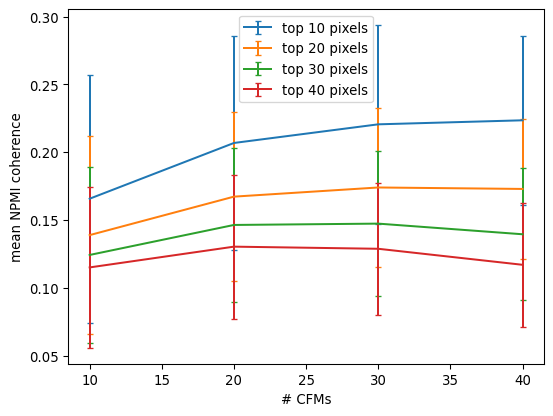

In [22]:
fig = model_pool.plot_mean_coherence_vs_num_CFMs(data=data)
fig.set_dpi(96)
fig.show

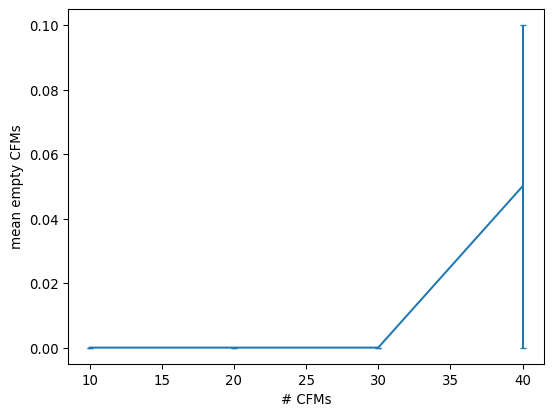

In [5]:
fig = model_pool.plot_mean_empty_vs_num_CFMs()
fig.set_dpi(96)
fig.show()

After ensuring that there are no empty topics, We pick a good balance between the two, i.e., 20 topics.

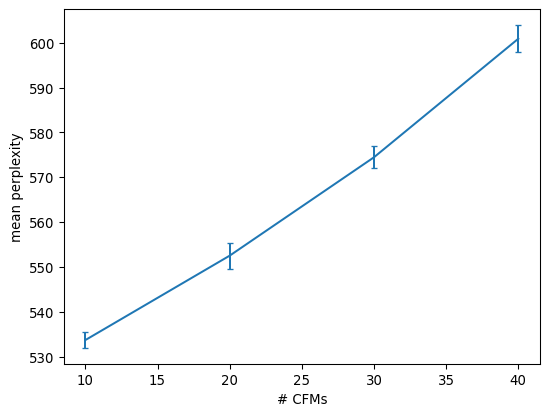

In [23]:
fig = model_pool.plot_mean_perplexity_vs_num_CFMs()
fig.set_dpi(96)
fig.show()